<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/main/notebooks/03_lightgbm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · LightGBM
**Project:** Explainable AI-Based Dyscalculia Screening and Adaptive Personalized Mathematics Intervention
**Stage 1:** Dyscalculia risk screening (DD vs TA) — OpenNeuro ds004791, 68 children aged 8–10

**Role: comparison model.** LightGBM is an alternative gradient-boosting implementation (leaf-wise growth,
histogram splits). It tests whether the boosting results depend on the specific library.

**Pipeline in this notebook**
1. Load the shared features and the saved outer CV splits from notebook 00 (no re-splitting).
2. Nested CV: 50 saved outer splits × inner stratified 3-fold grid search on ROC-AUC.
3. Report ROC-AUC, sensitivity, specificity, balanced accuracy, precision and F1 as mean ± SD.
4. Save metrics (`results/lightgbm.json`), out-of-fold probabilities (`results/lightgbm_oof.csv`),
   the final model refit on all children (`models/lightgbm.joblib`) and figures (`figures/`).

*Expected runtime on a standard Colab CPU runtime: about 3–6 minutes.*

## 1. Install missing packages
Colab already ships with numpy, pandas, scikit-learn, matplotlib, seaborn, XGBoost and LightGBM.
This cell only installs the packages that are missing in the current runtime, so it is safe to re-run.

In [ ]:
import importlib, subprocess, sys

REQUIRED = [
    ("sklearn", "scikit-learn"),
    ("xgboost", "xgboost"),
    ("lightgbm", "lightgbm"),
    ("joblib", "joblib"),
]
for import_name, pip_name in REQUIRED:
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
print("All required packages are available.")

All required packages are available.


## 2. Mount Google Drive and set the project folder
All notebooks share one project folder on Google Drive:

```
/content/drive/MyDrive/Dyscalculia_Stage1/
├── data/      ds004791_features.csv + shared configuration (features, X/y, CV splits)
├── results/   per-model metrics (.json) and out-of-fold probabilities (.csv)
├── models/    final models refit on all children (.joblib)
└── figures/   all plots
```
When the notebook is run outside Colab, a local `Dyscalculia_Stage1/` folder is used instead
(or the folder given by the `STAGE1_PROJECT_DIR` environment variable).

In [ ]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/Dyscalculia_Stage1'
except ImportError:  # running locally / outside Colab
    PROJECT_DIR = os.environ.get('STAGE1_PROJECT_DIR', os.path.abspath('Dyscalculia_Stage1'))

DATA_DIR    = os.path.join(PROJECT_DIR, 'data')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
FIGURES_DIR = os.path.join(PROJECT_DIR, 'figures')
for d in (DATA_DIR, RESULTS_DIR, MODELS_DIR, FIGURES_DIR):
    os.makedirs(d, exist_ok=True)

CONFIG_PATH = os.path.join(DATA_DIR, 'stage1_config.joblib')
print('Project folder:', PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Dyscalculia_Stage1


## 3. Imports

In [ ]:
import json, time, warnings
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')        # silence convergence / future warnings in the long CV loops
sns.set_theme(style='whitegrid', context='notebook')
np.random.seed(42)

## 4. Load the shared configuration from notebook 00
Every model uses **exactly the same** feature matrix, labels and outer cross-validation splits
(RepeatedStratifiedKFold, 5 folds x 10 repeats, `random_state=42`), created once in
`00_setup_and_data.ipynb`. Nothing is re-split here, which makes the per-fold scores of all
models directly comparable (a requirement for the paired corrected t-test in notebook 11).

In [ ]:
assert os.path.exists(CONFIG_PATH), 'Run 00_setup_and_data.ipynb first - shared config not found.'
cfg = joblib.load(CONFIG_PATH)

X            = cfg['X']                # pandas DataFrame, children x features
y            = cfg['y']                # numpy array, 1 = DD, 0 = TA
FEATURES     = cfg['features']
IDS          = cfg['ids']
OUTER_SPLITS = cfg['outer_splits']     # list of dicts: split_id, repeat, fold, train_idx, test_idx
N_SPLITS, N_REPEATS = cfg['n_splits'], cfg['n_repeats']
RANDOM_STATE = cfg['random_state']

print(f'Children: {len(y)}  (DD = {int(y.sum())}, TA = {int((y == 0).sum())})')
print(f'Features ({len(FEATURES)}): {FEATURES}')
print(f'Outer CV: {N_SPLITS} folds x {N_REPEATS} repeats = {len(OUTER_SPLITS)} train/test splits')

Children: 68  (DD = 30, TA = 38)
Features (12): ['SmallProblem_acc', 'LargeProblem_acc', 'Plus1_acc', 'SmallProblem_rt', 'LargeProblem_rt', 'NumberMatching_acc', 'NumberMatching_rt', 'general_acc', 'general_rt', 'math_specific_acc', 'math_specific_rt', 'STM5_acc']
Outer CV: 5 folds x 10 repeats = 50 train/test splits


## 5. Shared evaluation utilities
These helper functions are **identical in every model notebook** so that all models are evaluated the same way.

**Nested cross-validation**
* *Outer loop* (50 splits, loaded from notebook 00): gives an unbiased estimate of how the model performs on unseen children.
* *Inner loop* (stratified 3-fold grid search on the outer-training part only, scoring = ROC-AUC): chooses the hyperparameters.
  The outer-test children are never seen during tuning, so there is no information leakage.
* Imputation and scaling are part of the `Pipeline`, so they are also learned on training folds only.

**Metrics** (DD = positive class, decision threshold 0.5)

| Metric | Meaning for screening |
|---|---|
| ROC-AUC (primary) | Threshold-free ability to rank DD children above TA children |
| Recall / sensitivity | Share of DD children that are flagged (missed cases are the costly error in screening) |
| Specificity | Share of TA children correctly *not* flagged |
| Balanced accuracy | Mean of sensitivity and specificity (robust to the 30/38 imbalance) |
| Precision | Share of flagged children that really are DD |
| F1 | Harmonic mean of precision and recall |

Each metric is computed on every outer test fold and reported as **mean ± SD over the 50 folds**.

In [ ]:
INNER_SPLITS = 3       # inner grid-search folds
N_JOBS       = -1      # parallelise the grid search over all CPU cores
THRESHOLD    = 0.5     # probability threshold for flagging a child as at-risk

METRICS = ['auc', 'recall', 'specificity', 'balanced_accuracy', 'precision', 'f1']
METRIC_LABELS = {'auc': 'ROC-AUC', 'recall': 'Recall (sensitivity)', 'specificity': 'Specificity',
                 'balanced_accuracy': 'Balanced accuracy', 'precision': 'Precision', 'f1': 'F1'}


def classification_metrics(y_true, prob, threshold=THRESHOLD):
    """All screening metrics for one test fold (DD = positive class)."""
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    recall      = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    precision   = tp / (tp + fp) if (tp + fp) else 0.0       # zero_division = 0 convention
    f1          = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {'auc': roc_auc_score(y_true, prob), 'recall': recall, 'specificity': specificity,
            'balanced_accuracy': (recall + specificity) / 2, 'precision': precision, 'f1': f1}


def _jsonable(params):
    """Convert hyperparameter values (e.g. tuples) into JSON-friendly types."""
    return {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in params.items()}


def run_nested_cv(build_estimator, param_grid, fit_params_fn=None, verbose=True):
    """Nested CV over the saved outer splits.

    build_estimator(y_train) -> unfitted sklearn estimator/pipeline (y_train lets us set class weights
                                 such as scale_pos_weight from the training fold only)
    fit_params_fn(y_train)   -> optional dict of fit parameters (e.g. sample weights)
    Returns per-fold metrics, out-of-fold probabilities and the runtime in seconds.
    """
    fold_rows, oof_rows = [], []
    t0 = time.time()
    for s in OUTER_SPLITS:
        tr, te = s['train_idx'], s['test_idx']
        X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]

        inner_cv = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE + s['split_id'])
        search = GridSearchCV(build_estimator(y_tr), param_grid, scoring='roc_auc', cv=inner_cv,
                              n_jobs=N_JOBS, refit=True, error_score='raise')
        fit_params = fit_params_fn(y_tr) if fit_params_fn is not None else {}
        search.fit(X_tr, y_tr, **fit_params)
        prob = search.predict_proba(X_te)[:, 1]

        fold_rows.append({'split_id': s['split_id'], 'repeat': s['repeat'], 'fold': s['fold'],
                          **classification_metrics(y_te, prob),
                          'inner_best_auc': search.best_score_,
                          'best_params': _jsonable(search.best_params_)})
        for i, p in zip(te, prob):
            oof_rows.append({'row_index': int(i), 'child_id': IDS[i], 'repeat': s['repeat'], 'fold': s['fold'],
                             'y_true': int(y[i]), 'prob_dd': float(p)})

        if verbose and s['fold'] == N_SPLITS - 1:
            done = pd.DataFrame(fold_rows)
            print(f"Repeat {s['repeat'] + 1:2d}/{N_REPEATS} done | running mean AUC = {done['auc'].mean():.3f} "
                  f"| elapsed {time.time() - t0:.0f}s")
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows), time.time() - t0


def summarise(fold_df):
    """Mean +- SD over the outer folds for every metric."""
    rows = []
    for m in METRICS:
        mean, sd = fold_df[m].mean(), fold_df[m].std(ddof=1)
        rows.append({'Metric': METRIC_LABELS[m], 'Mean': mean, 'SD': sd, 'Mean ± SD': f'{mean:.3f} ± {sd:.3f}'})
    return pd.DataFrame(rows).set_index('Metric')


def repeat_pooled_auc(oof_df):
    """AUC of the pooled out-of-fold predictions within each repeat (each repeat covers every child once)."""
    return oof_df.groupby('repeat').apply(lambda d: roc_auc_score(d['y_true'], d['prob_dd'])).values


def child_level_oof(oof_df):
    """Average each child's out-of-fold probability over the 10 repeats."""
    return oof_df.groupby(['row_index', 'child_id', 'y_true'], as_index=False)['prob_dd'].mean()


def hyperparameter_stability(fold_df, top=5):
    """How often each hyperparameter combination was chosen by the inner grid search."""
    counts = fold_df['best_params'].apply(lambda p: json.dumps(p, sort_keys=True)).value_counts()
    out = counts.head(top).rename('times chosen (of %d)' % len(fold_df)).to_frame()
    out.index.name = 'hyperparameters'
    return out


def fit_final_model(build_estimator, param_grid, fit_params_fn=None):
    """Tune on ALL children (3-fold grid search) and refit - this is the deployable model.
    Its performance is the nested-CV estimate above, NOT its (optimistic) training score."""
    cv = StratifiedKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    search = GridSearchCV(build_estimator(y), param_grid, scoring='roc_auc', cv=cv, n_jobs=N_JOBS, refit=True)
    search.fit(X, y, **(fit_params_fn(y) if fit_params_fn is not None else {}))
    return search


def save_outputs(model_name, display_name, fold_df, oof_df, final_search, param_grid, runtime):
    summary = {m: {'mean': float(fold_df[m].mean()), 'sd': float(fold_df[m].std(ddof=1))} for m in METRICS}
    child = child_level_oof(oof_df)
    results = {
        'model_name': model_name,
        'display_name': display_name,
        'n_children': int(len(y)), 'n_dd': int(y.sum()), 'n_ta': int((y == 0).sum()),
        'features': FEATURES,
        'outer_cv': f'RepeatedStratifiedKFold({N_SPLITS} folds x {N_REPEATS} repeats, random_state={RANDOM_STATE})',
        'inner_cv': f'StratifiedKFold({INNER_SPLITS}) grid search, scoring=roc_auc',
        'threshold': THRESHOLD,
        'param_grid': {k: [str(v) if not isinstance(v, (int, float, str, bool, type(None))) else v for v in vals]
                       for k, vals in param_grid.items()},
        'summary': summary,
        'fold_auc': fold_df['auc'].tolist(),
        'fold_metrics': fold_df.to_dict(orient='records'),
        'repeat_pooled_auc': repeat_pooled_auc(oof_df).tolist(),
        'child_mean_prob_auc': float(roc_auc_score(child['y_true'], child['prob_dd'])),
        'final_model_best_params': _jsonable(final_search.best_params_),
        'final_model_inner_cv_auc': float(final_search.best_score_),
        'runtime_seconds': float(runtime),
        'created': datetime.now().isoformat(timespec='seconds'),
    }
    paths = {'json': os.path.join(RESULTS_DIR, f'{model_name}.json'),
             'oof':  os.path.join(RESULTS_DIR, f'{model_name}_oof.csv'),
             'model': os.path.join(MODELS_DIR, f'{model_name}.joblib')}
    with open(paths['json'], 'w') as f:
        json.dump(results, f, indent=2, default=float)
    oof_df.to_csv(paths['oof'], index=False)
    joblib.dump(final_search.best_estimator_, paths['model'])
    for k, p in paths.items():
        print(f'Saved {k:5s} -> {p}')
    return results


def plot_confusion_matrix(model_name, display_name, oof_df):
    """Child-level confusion matrix: each child's out-of-fold probability averaged over the 10 repeats."""
    child = child_level_oof(oof_df)
    pred = (child['prob_dd'] >= THRESHOLD).astype(int)
    cm = confusion_matrix(child['y_true'], pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(cm, display_labels=['TA', 'DD']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{display_name}\nSensitivity {tp / (tp + fn):.2f} | Specificity {tn / (tn + fp):.2f}', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    fig.tight_layout()
    path = os.path.join(FIGURES_DIR, f'{model_name}_confusion_matrix.png')
    fig.savefig(path, dpi=200, bbox_inches='tight'); plt.show()
    print('Saved ->', path)


def mean_roc(oof_df, grid=np.linspace(0, 1, 101)):
    """Mean +- SD ROC curve over the repeats (one pooled out-of-fold ROC curve per repeat)."""
    tprs = []
    for _, d in oof_df.groupby('repeat'):
        fpr, tpr, _ = roc_curve(d['y_true'], d['prob_dd'])
        t = np.interp(grid, fpr, tpr); t[0] = 0.0
        tprs.append(t)
    tprs = np.array(tprs)
    return grid, tprs.mean(axis=0), tprs.std(axis=0, ddof=1), tprs


def plot_roc(model_name, display_name, oof_df, fold_df):
    grid, mean_tpr, sd_tpr, tprs = mean_roc(oof_df)
    fig, ax = plt.subplots(figsize=(5, 4.6))
    for t in tprs:
        ax.plot(grid, t, color='tab:blue', alpha=0.15, lw=1)
    ax.plot(grid, mean_tpr, color='tab:blue', lw=2.2,
            label=f"Mean ROC (fold AUC = {fold_df['auc'].mean():.3f} ± {fold_df['auc'].std(ddof=1):.3f})")
    ax.fill_between(grid, np.clip(mean_tpr - sd_tpr, 0, 1), np.clip(mean_tpr + sd_tpr, 0, 1),
                    color='tab:blue', alpha=0.2, label='± 1 SD over repeats')
    ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Chance')
    ax.set_xlabel('False positive rate (1 - specificity)'); ax.set_ylabel('True positive rate (sensitivity)')
    ax.set_title(f'{display_name} - out-of-fold ROC ({N_REPEATS} repeats)', fontsize=10)
    ax.legend(loc='lower right', fontsize=8); ax.set_aspect('equal')
    fig.tight_layout()
    path = os.path.join(FIGURES_DIR, f'{model_name}_roc_curve.png')
    fig.savefig(path, dpi=200, bbox_inches='tight'); plt.show()
    print('Saved ->', path)

## 6. Model definition and hyperparameter grid
* Shallow trees (`max_depth` 2–3, `num_leaves` ≤ 7), low learning rate, row/column subsampling 0.8.
* `min_child_samples` is lowered from the default 20 to 5–10 — otherwise, with ~36 children per inner training fold,
  hardly any split would be allowed.
* `class_weight='balanced'` for the 30/38 imbalance.

In [ ]:
MODEL_NAME   = 'lightgbm'
DISPLAY_NAME = 'LightGBM'

def build_estimator(y_train):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf', LGBMClassifier(num_leaves=7, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               class_weight='balanced', n_jobs=1, random_state=RANDOM_STATE, verbose=-1)),
    ])

PARAM_GRID = {
    'clf__max_depth': [2, 3],
    'clf__learning_rate': [0.03, 0.1],
    'clf__n_estimators': [100, 300],
    'clf__min_child_samples': [5, 10],
}
FIT_PARAMS_FN = None

n_combos = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f'{n_combos} hyperparameter combinations x {INNER_SPLITS} inner folds x {len(OUTER_SPLITS)} outer splits '
      f'= {n_combos * INNER_SPLITS * len(OUTER_SPLITS)} model fits')

16 hyperparameter combinations x 3 inner folds x 50 outer splits = 2400 model fits


## 7. Run nested cross-validation
For each of the 50 outer splits the grid search is run on the outer-training children only;
the best configuration is refit on them and then scores the held-out outer-test children.

In [ ]:
fold_df, oof_df, runtime = run_nested_cv(build_estimator, PARAM_GRID, FIT_PARAMS_FN)
print(f'\nNested CV finished in {runtime / 60:.1f} min')

Repeat  1/10 done | running mean AUC = 0.710 | elapsed 12s
Repeat  2/10 done | running mean AUC = 0.681 | elapsed 25s
Repeat  3/10 done | running mean AUC = 0.700 | elapsed 37s
Repeat  4/10 done | running mean AUC = 0.686 | elapsed 44s
Repeat  5/10 done | running mean AUC = 0.680 | elapsed 50s
Repeat  6/10 done | running mean AUC = 0.678 | elapsed 57s
Repeat  7/10 done | running mean AUC = 0.677 | elapsed 62s
Repeat  8/10 done | running mean AUC = 0.680 | elapsed 68s
Repeat  9/10 done | running mean AUC = 0.686 | elapsed 75s
Repeat 10/10 done | running mean AUC = 0.687 | elapsed 80s

Nested CV finished in 1.3 min


## 8. Results: mean ± SD over the 50 outer test folds
Below the main table we also show (a) the AUC of the pooled out-of-fold predictions within each repeat and
(b) how stable the hyperparameter choice was across the outer folds — a frequently chosen configuration
indicates that tuning was not just fitting noise.

In [ ]:
summary_df = summarise(fold_df)
display(summary_df[['Mean ± SD']])

pooled = repeat_pooled_auc(oof_df)
print(f'Pooled out-of-fold AUC per repeat: {pooled.mean():.3f} ± {pooled.std(ddof=1):.3f} '
      f'(range {pooled.min():.3f}-{pooled.max():.3f})')
print(f"Mean inner-CV AUC of the selected configurations: {fold_df['inner_best_auc'].mean():.3f}")

print('\nMost frequently selected hyperparameters:')
display(hyperparameter_stability(fold_df))

,Mean ± SD
Metric,
ROC-AUC,0.687 ± 0.126
Recall (sensitivity),0.567 ± 0.184
Specificity,0.701 ± 0.158
Balanced accuracy,0.634 ± 0.123
Precision,0.609 ± 0.147
F1,0.576 ± 0.150


Pooled out-of-fold AUC per repeat: 0.674 ± 0.030 (range 0.627-0.725)
Mean inner-CV AUC of the selected configurations: 0.739

Most frequently selected hyperparameters:


,times chosen (of 50)
hyperparameters,
"{""clf__learning_rate"": 0.03, ""clf__max_depth"": 2, ""clf__min_child_samples"": 10, ""clf__n_estimators"": 100}",37
"{""clf__learning_rate"": 0.1, ""clf__max_depth"": 2, ""clf__min_child_samples"": 10, ""clf__n_estimators"": 100}",4
"{""clf__learning_rate"": 0.03, ""clf__max_depth"": 2, ""clf__min_child_samples"": 10, ""clf__n_estimators"": 300}",4
"{""clf__learning_rate"": 0.1, ""clf__max_depth"": 2, ""clf__min_child_samples"": 10, ""clf__n_estimators"": 300}",2
"{""clf__learning_rate"": 0.03, ""clf__max_depth"": 2, ""clf__min_child_samples"": 5, ""clf__n_estimators"": 300}",1


## 9. Figures: confusion matrix and ROC curve
* **Confusion matrix** – each child's out-of-fold probability is averaged over the 10 repeats and thresholded at 0.5,
  so the matrix shows all 68 children exactly once.
* **ROC curve** – one pooled out-of-fold ROC curve per repeat (thin lines), their mean (thick line) and ± 1 SD band.

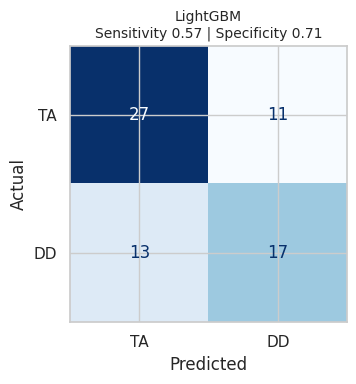

Saved -> /content/drive/MyDrive/Dyscalculia_Stage1/figures/lightgbm_confusion_matrix.png


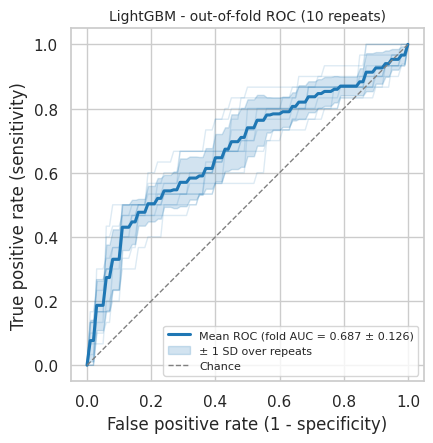

Saved -> /content/drive/MyDrive/Dyscalculia_Stage1/figures/lightgbm_roc_curve.png


In [ ]:
plot_confusion_matrix(MODEL_NAME, DISPLAY_NAME, oof_df)
plot_roc(MODEL_NAME, DISPLAY_NAME, oof_df, fold_df)

## 10. Refit the final model on all children and save everything
The final model is tuned with the same 3-fold grid search on all 68 children and refit.
**Its expected performance on new children is the nested-CV estimate above**, not its training score.

In [ ]:
final_search = fit_final_model(build_estimator, PARAM_GRID, FIT_PARAMS_FN)
print('Final hyperparameters:', final_search.best_params_)
print(f'Final 3-fold CV AUC on all data (optimistic, for reference only): {final_search.best_score_:.3f}\n')

results = save_outputs(MODEL_NAME, DISPLAY_NAME, fold_df, oof_df, final_search, PARAM_GRID, runtime)

Final hyperparameters: {'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__min_child_samples': 10, 'clf__n_estimators': 100}
Final 3-fold CV AUC on all data (optimistic, for reference only): 0.743

Saved json  -> /content/drive/MyDrive/Dyscalculia_Stage1/results/lightgbm.json
Saved oof   -> /content/drive/MyDrive/Dyscalculia_Stage1/results/lightgbm_oof.csv
Saved model -> /content/drive/MyDrive/Dyscalculia_Stage1/models/lightgbm.joblib


## Summary

In [ ]:
s = results['summary']
print(f"{DISPLAY_NAME}: ROC-AUC {s['auc']['mean']:.3f} ± {s['auc']['sd']:.3f} | "
      f"sensitivity {s['recall']['mean']:.3f} ± {s['recall']['sd']:.3f} | "
      f"specificity {s['specificity']['mean']:.3f} ± {s['specificity']['sd']:.3f} | "
      f"balanced accuracy {s['balanced_accuracy']['mean']:.3f} ± {s['balanced_accuracy']['sd']:.3f}")
print('Next: run the remaining model notebooks, then 11_model_comparison_and_selection.ipynb')

LightGBM: ROC-AUC 0.687 ± 0.126 | sensitivity 0.567 ± 0.184 | specificity 0.701 ± 0.158 | balanced accuracy 0.634 ± 0.123
Next: run the remaining model notebooks, then 11_model_comparison_and_selection.ipynb
